# Projeto Health&Life Analytics
**Objetivo:** Analisar o perfil dos clientes e entender o impacto do consumo de café e cafeína na qualidade do sono, nível de estresse e saúde geral.

---
### Configuração Inicial do Ambiente
Importação das bibliotecas essenciais para manipulação de dados e visualização gráfica.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações globais para visualizações gráficas
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


## Parte 1: Análise Exploratória de Dados (EDA)

## Passo 1: Carregamento da Base de Dados
Carregando o arquivo `synthetic_coffee_health_10000.csv` para dar início às análises.

In [6]:
# Carregando o dataset
df = pd.read_csv('synthetic_coffee_health_10000.csv')

# Exibindo as 5 primeiras linhas do dataframe
df.head()

,ID,Age,Gender,Country,Coffee_Intake,Caffeine_mg,Sleep_Hours,Sleep_Quality,BMI,Heart_Rate,Stress_Level,Physical_Activity_Hours,Health_Issues,Occupation,Smoking,Alcohol_Consumption
0,1,40,Male,Germany,3.5,328.1,7.5,Good,24.9,78,Low,14.5,NaN,Other,0,0
1,2,33,Male,Germany,1.0,94.1,6.2,Good,20.0,67,Low,11.0,NaN,Service,0,0
2,3,42,Male,Brazil,5.3,503.7,5.9,Fair,22.7,59,Medium,11.2,Mild,Office,0,0
3,4,53,Male,Germany,2.6,249.2,7.3,Good,24.7,71,Low,6.6,Mild,Other,0,0
4,5,32,Female,Spain,3.1,298.0,5.3,Fair,24.1,76,Medium,8.5,Mild,Student,0,1


## Passo 2: Diagnóstico e Integridade dos Dados
Verificação das dimensões do dataset (linhas e colunas), nomes das colunas, tipos de dados, contagem de valores nulos e presença de linhas duplicadas.

In [7]:
print("=== DIMENSÕES DO DATASET ===")
print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}\n")

print("=== TIPOS DE DADOS E VALORES NÃO-NULOS ===")
df.info()

print("\n=== VERIFICAÇÃO DE VALORES NULOS ===")
print(df.isnull().sum())

print("\n=== VERIFICAÇÃO DE LINHAS DUPLICADAS ===")
print(f"Total de registros duplicados: {df.duplicated().sum()}")

=== DIMENSÕES DO DATASET ===
Linhas: 10000 | Colunas: 16

=== TIPOS DE DADOS E VALORES NÃO-NULOS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       10000 non-null  int64  
 1   Age                      10000 non-null  int64  
 2   Gender                   10000 non-null  object 
 3   Country                  10000 non-null  object 
 4   Coffee_Intake            10000 non-null  float64
 5   Caffeine_mg              10000 non-null  float64
 6   Sleep_Hours              10000 non-null  float64
 7   Sleep_Quality            10000 non-null  object 
 8   BMI                      10000 non-null  float64
 9   Heart_Rate               10000 non-null  int64  
 10  Stress_Level             10000 non-null  object 
 11  Physical_Activity_Hours  10000 non-null  float64
 12  Health_Issues            4059 

## Passo 3: Estatísticas Descritivas Iniciais
Geração de métricas estatísticas (média, mediana, desvio padrão, mínimos e máximos) para variáveis numéricas e contagem para categóricas.

In [8]:
# Estatísticas descritivas das variáveis numéricas
print("=== RESUMO ESTATÍSTICO (NUMÉRICO) ===")
display(df.describe().T)

# Estatísticas descritivas das variáveis categóricas
print("\n=== RESUMO ESTATÍSTICO (CATEGÓRICO) ===")
display(df.describe(include=['O', 'bool']).T)

=== RESUMO ESTATÍSTICO (NUMÉRICO) ===


,count,mean,std,min,25%,50%,75%,max
ID,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.250,10000.0
Age,10000.0,34.94910,11.160939,18.0,26.00,34.0,43.000,80.0
Coffee_Intake,10000.0,2.50923,1.450248,0.0,1.50,2.5,3.500,8.2
Caffeine_mg,10000.0,238.41101,137.748815,0.0,138.75,235.4,332.025,780.3
Sleep_Hours,10000.0,6.63622,1.222055,3.0,5.80,6.6,7.500,10.0
BMI,10000.0,23.98686,3.906411,15.0,21.30,24.0,26.600,38.2
Heart_Rate,10000.0,70.61780,9.822951,50.0,64.00,71.0,77.000,109.0
Physical_Activity_Hours,10000.0,7.48704,4.315180,0.0,3.70,7.5,11.200,15.0
Smoking,10000.0,0.20040,0.400320,0.0,0.00,0.0,0.000,1.0
Alcohol_Consumption,10000.0,0.30070,0.458585,0.0,0.00,0.0,1.000,1.0



=== RESUMO ESTATÍSTICO (CATEGÓRICO) ===


,count,unique,top,freq
Gender,10000,3,Female,5001
Country,10000,20,Canada,543
Sleep_Quality,10000,4,Good,5637
Stress_Level,10000,3,Low,6989
Health_Issues,4059,3,Mild,3579
Occupation,10000,5,Office,2073


## Passo 4: Análise das Variáveis Numéricas
Exploração detalhada das distribuições numéricas através de **histogramas com curva de densidade (KDE)** e **boxplots** para identificação de outliers e simetria dos dados.

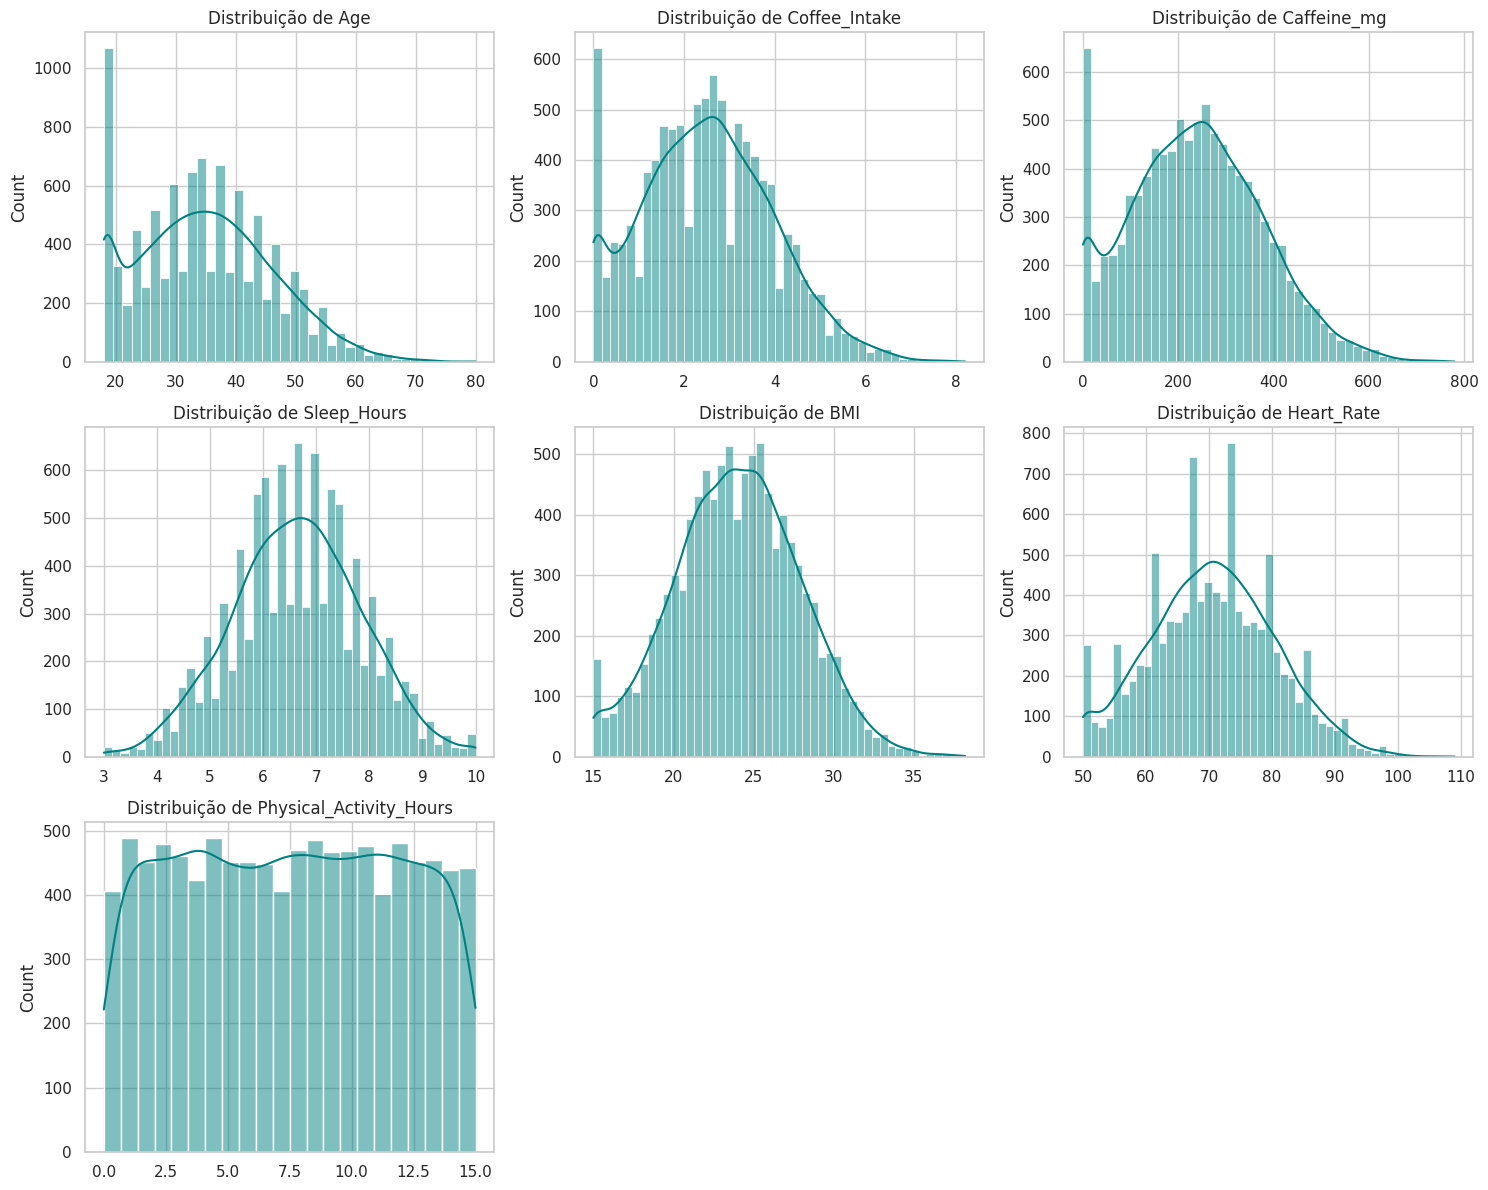

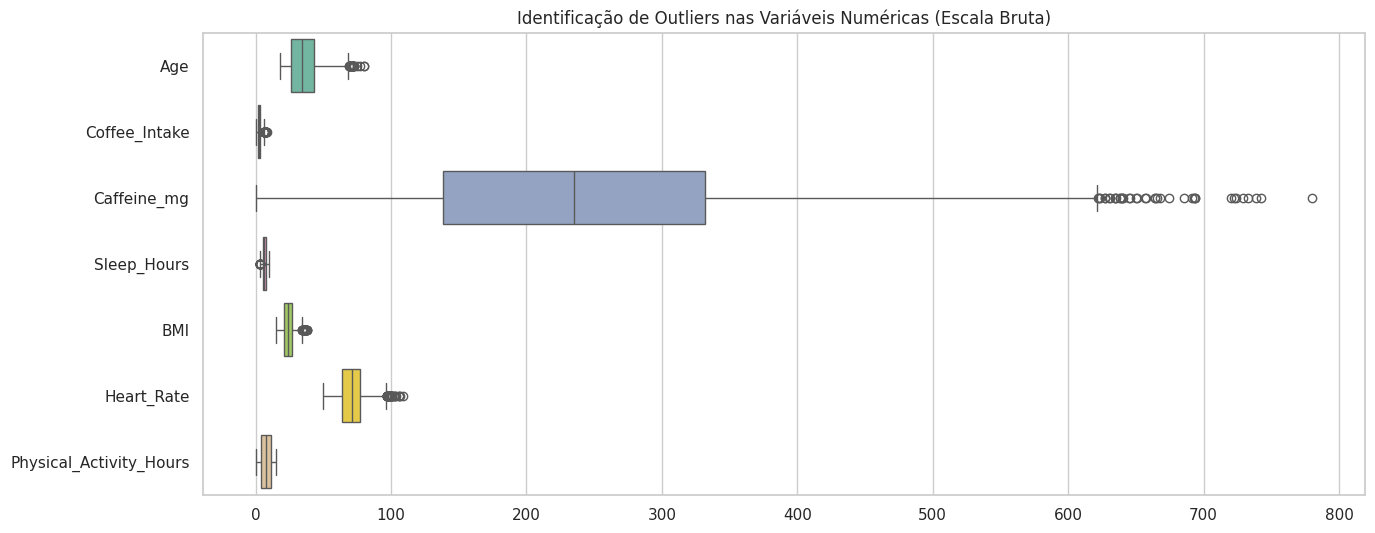

In [9]:
num_cols = ['Age', 'Coffee_Intake', 'Caffeine_mg', 'Sleep_Hours', 'BMI', 'Heart_Rate', 'Physical_Activity_Hours']

# Histogramas de Distribuição
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color='teal')
    axes[i].set_title(f'Distribuição de {col}')
    axes[i].set_xlabel('')

# Remover subplots vazios
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# Boxplots para detecção de Outliers
plt.figure(figsize=(15, 6))
sns.boxplot(data=df[num_cols], orient='h', palette='Set2')
plt.title('Identificação de Outliers nas Variáveis Numéricas (Escala Bruta)')
plt.show()

## Passo 5: Análise das Variáveis Categóricas
Análise da proporção de clientes por perfil categórico (gênero, país, nível de estresse, qualidade do sono, saúde e ocupação) utilizando gráficos de barras e gráfico de pizza/rosca.

/tmp/ipykernel_10538/2279087044.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Sleep_Quality', order=['Poor', 'Fair', 'Good', 'Excellent'], ax=axes[0, 0], palette='Blues_r')
/tmp/ipykernel_10538/2279087044.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Stress_Level', order=['Low', 'Medium', 'High'], ax=axes[0, 1], palette='Reds')
/tmp/ipykernel_10538/2279087044.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df[df['Country'].isin(top_countries)], y='Country', order=top_countries, ax=axes[1, 0

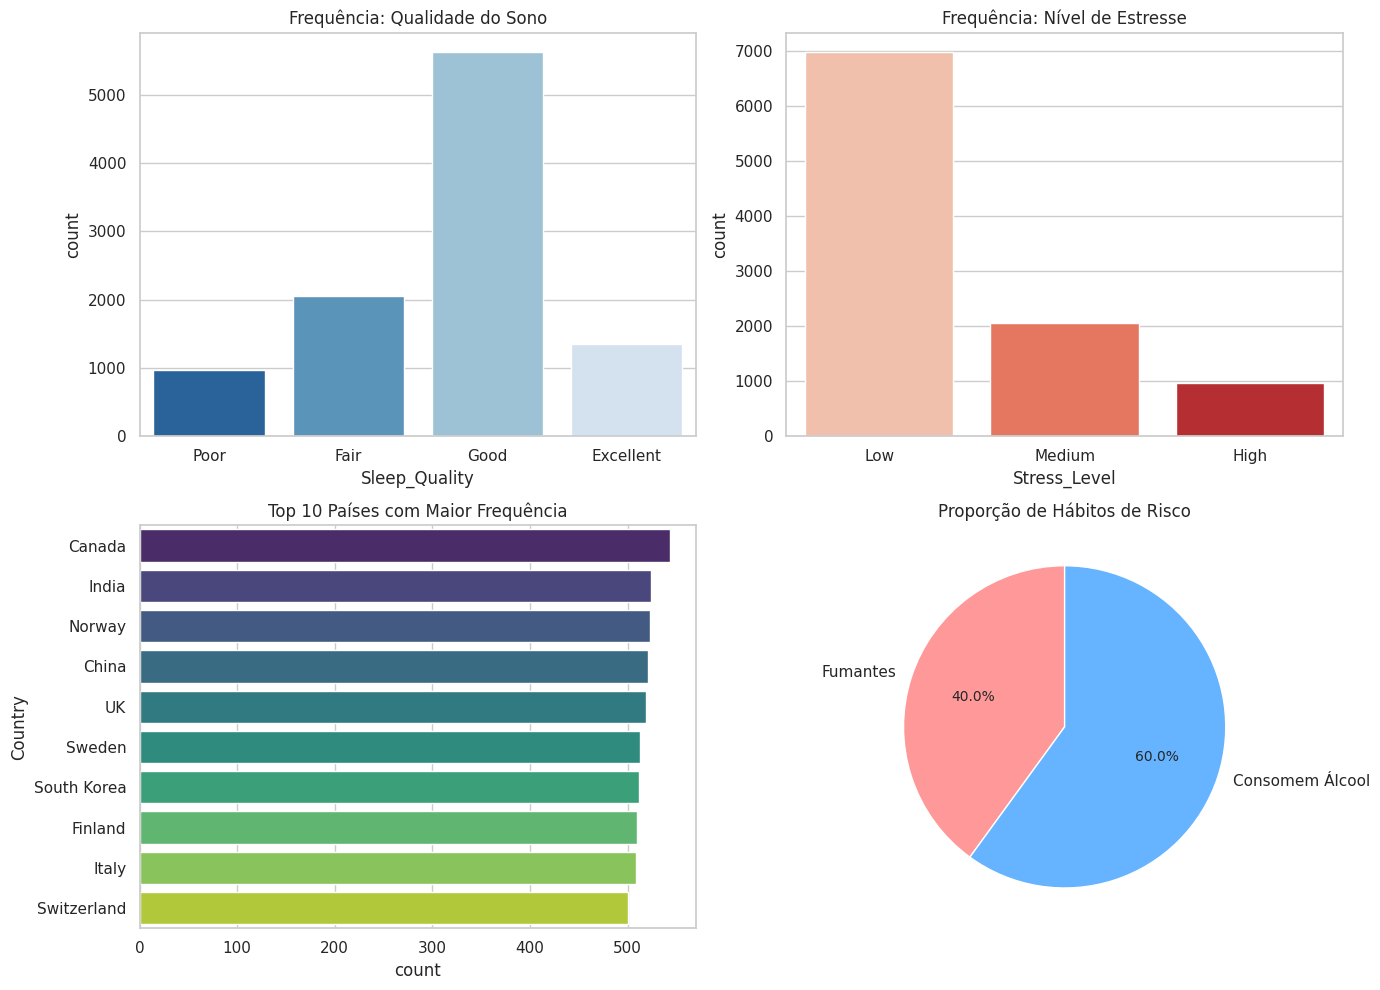

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Qualidade do Sono
sns.countplot(data=df, x='Sleep_Quality', order=['Poor', 'Fair', 'Good', 'Excellent'], ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Frequência: Qualidade do Sono')

# 2. Nível de Estresse
sns.countplot(data=df, x='Stress_Level', order=['Low', 'Medium', 'High'], ax=axes[0, 1], palette='Reds')
axes[0, 1].set_title('Frequência: Nível de Estresse')

# 3. Top 10 Países com mais Clientes
top_countries = df['Country'].value_counts().head(10).index
sns.countplot(data=df[df['Country'].isin(top_countries)], y='Country', order=top_countries, ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title('Top 10 Países com Maior Frequência')

# 4. Proporção de Hábitos de Risco (Fumantes vs Álcool)
habits_data = [df['Smoking'].sum(), df['Alcohol_Consumption'].sum()]
axes[1, 1].pie(habits_data, labels=['Fumantes', 'Consomem Álcool'], autopct='%1.1f%%', colors=['#ff9999','#66b3ff'], startangle=90)
axes[1, 1].set_title('Proporção de Hábitos de Risco')

plt.tight_layout()
plt.show()

## Passo 6: Investigação de Correlações e Hipóteses de Negócio
Nesta etapa cruzamos variáveis para testar se o consumo de café realmente prejudica o sono e se o estresse atua como fator agravante.

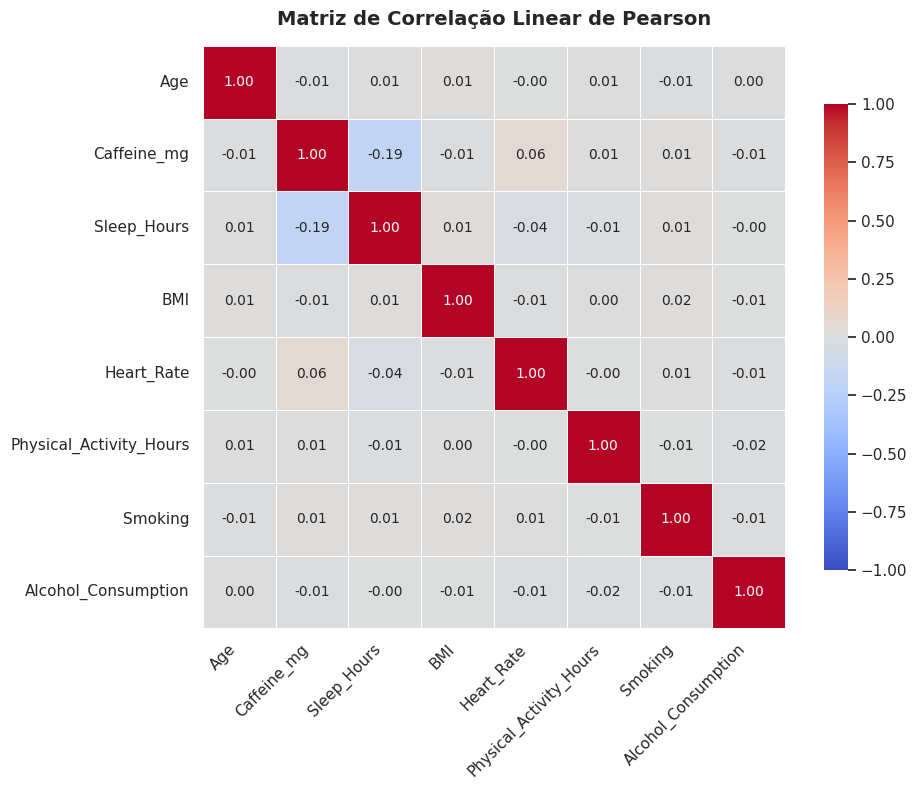

In [11]:
# Matriz de Correlação Linear de Pearson
plt.figure(figsize=(10, 8))

# Selecionar variáveis numéricas
numeric_df = df.drop(columns=['ID','Coffee_Intake'], errors='ignore').select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr(method='pearson')

# Heatmap completo (sem máscara)
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1, vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"shrink": 0.8}
)

plt.title('Matriz de Correlação Linear de Pearson', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

/tmp/ipykernel_10538/2088368892.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


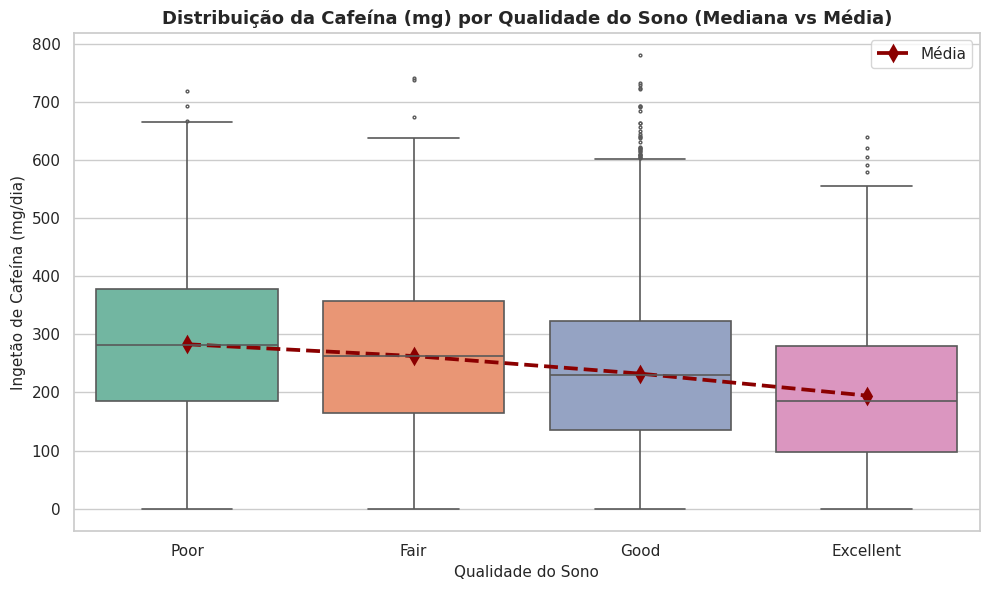

In [12]:
plt.figure(figsize=(10, 6))

order_sleep = ['Poor', 'Fair', 'Good', 'Excellent']

sns.boxplot(
    data=df,
    x='Sleep_Quality',
    y='Caffeine_mg',
    order=order_sleep,
    palette='Set2',
    fliersize=2,
    linewidth=1.2
)

# Adicionar média em ponto vermelho para comparação com a mediana
sns.pointplot(
    data=df,
    x='Sleep_Quality',
    y='Caffeine_mg',
    order=order_sleep,
    color='darkred',
    estimator='mean',
    errorbar=None,
    markers='d',
    linestyles='--',
    label='Média'
)

plt.title('Distribuição da Cafeína (mg) por Qualidade do Sono (Mediana vs Média)', fontsize=13, fontweight='bold')
plt.xlabel('Qualidade do Sono', fontsize=11)
plt.ylabel('Ingetão de Cafeína (mg/dia)', fontsize=11)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

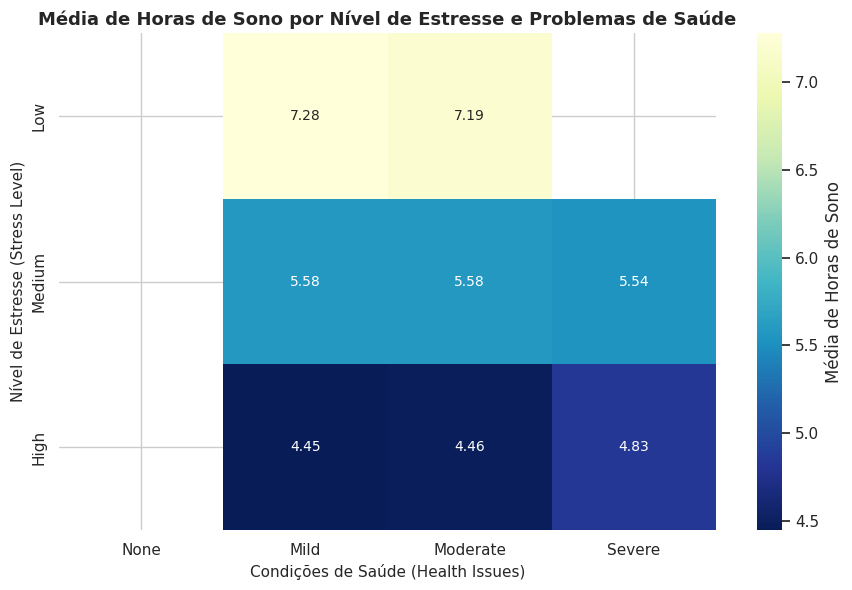

In [13]:
# Tabela pivô com a média de horas de sono
pivot_sleep = df.pivot_table(
    index='Stress_Level',
    columns='Health_Issues',
    values='Sleep_Hours',
    aggfunc='mean'
).reindex(index=['Low', 'Medium', 'High'], columns=['None', 'Mild', 'Moderate', 'Severe'])

plt.figure(figsize=(9, 6))
sns.heatmap(
    pivot_sleep,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu_r', # Cores mais escuras = Menos horas de sono
    cbar_kws={'label': 'Média de Horas de Sono'}
)

plt.title('Média de Horas de Sono por Nível de Estresse e Problemas de Saúde', fontsize=13, fontweight='bold')
plt.xlabel('Condições de Saúde (Health Issues)', fontsize=11)
plt.ylabel('Nível de Estresse (Stress Level)', fontsize=11)
plt.tight_layout()
plt.show()

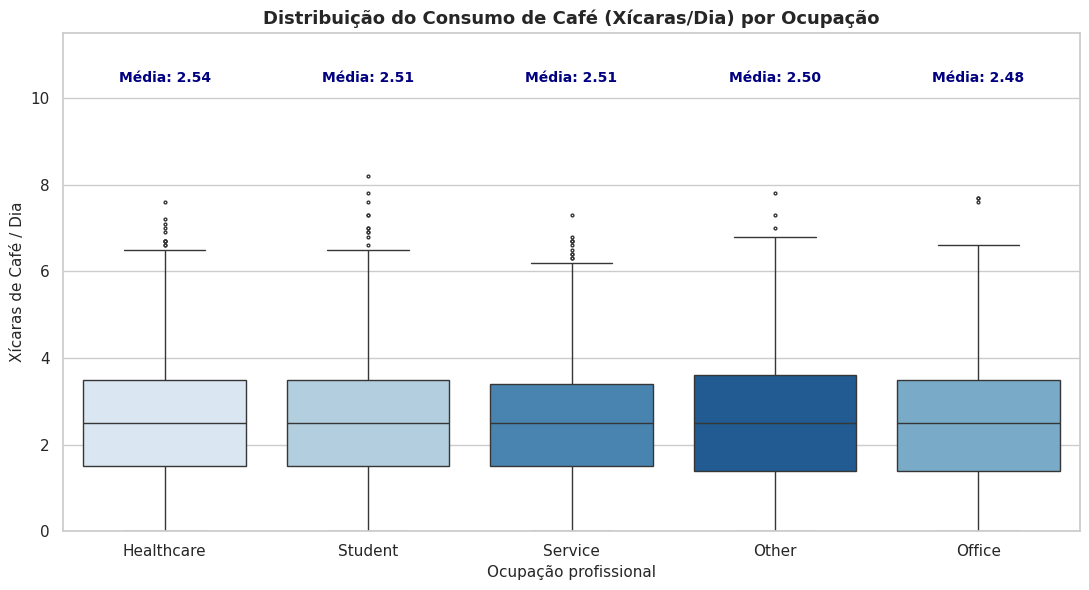

In [14]:
plt.figure(figsize=(11, 6))

# Ordenar por ocupação
occ_order = df.groupby('Occupation')['Coffee_Intake'].mean().sort_values(ascending=False).index

# Boxplot para mostrar a distribuição completa em cada profissão
ax = sns.boxplot(
    data=df,
    x='Occupation',
    y='Coffee_Intake',
    order=occ_order,
    palette='Blues_r',
    hue='Occupation',
    legend=False,
    fliersize=2
)

# Adicionar o valor numérico exato da média no topo de cada boxplot
means = df.groupby('Occupation')['Coffee_Intake'].mean().reindex(occ_order)
for i, mean_val in enumerate(means):
    ax.text(
        i, 10.3,
        f'Média: {mean_val:.2f}',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        color='navy'
    )

plt.ylim(0, 11.5)
plt.title('Distribuição do Consumo de Café (Xícaras/Dia) por Ocupação', fontsize=13, fontweight='bold')
plt.xlabel('Ocupação profissional', fontsize=11)
plt.ylabel('Xícaras de Café / Dia', fontsize=11)
plt.tight_layout()
plt.show()

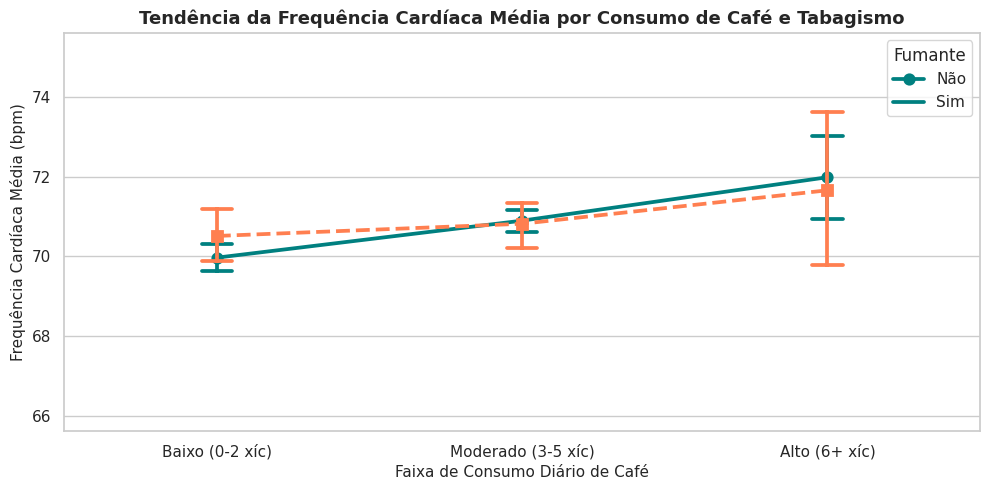

In [15]:
# 1. Criar faixas de consumo de café
df['Coffee_Group'] = pd.cut(
    df['Coffee_Intake'],
    bins=[-1, 2, 5, 10],
    labels=['Baixo (0-2 xíc)', 'Moderado (3-5 xíc)', 'Alto (6+ xíc)']
)

plt.figure(figsize=(10, 5))

# Pointplot para destacar médias e tendências sem a poluição das barras
ax = sns.pointplot(
    data=df,
    x='Coffee_Group',
    y='Heart_Rate',
    hue='Smoking',
    palette={0: 'teal', 1: 'coral'},
    markers=['o', 's'],
    linestyles=['-', '--'],
    capsize=0.1,
    errorbar=('ci', 95)
)

# Ajuste de escala focado no intervalo médio (zoom no impacto real)
mean_hr = df['Heart_Rate'].mean()
plt.ylim(mean_hr - 5, mean_hr + 5)

plt.title('Tendência da Frequência Cardíaca Média por Consumo de Café e Tabagismo', fontsize=13, fontweight='bold')
plt.xlabel('Faixa de Consumo Diário de Café', fontsize=11)
plt.ylabel('Frequência Cardíaca Média (bpm)', fontsize=11)
plt.legend(title='Fumante', labels=['Não', 'Sim'])
plt.tight_layout()
plt.show()

df.drop(columns=['Coffee_Group'], inplace=True)

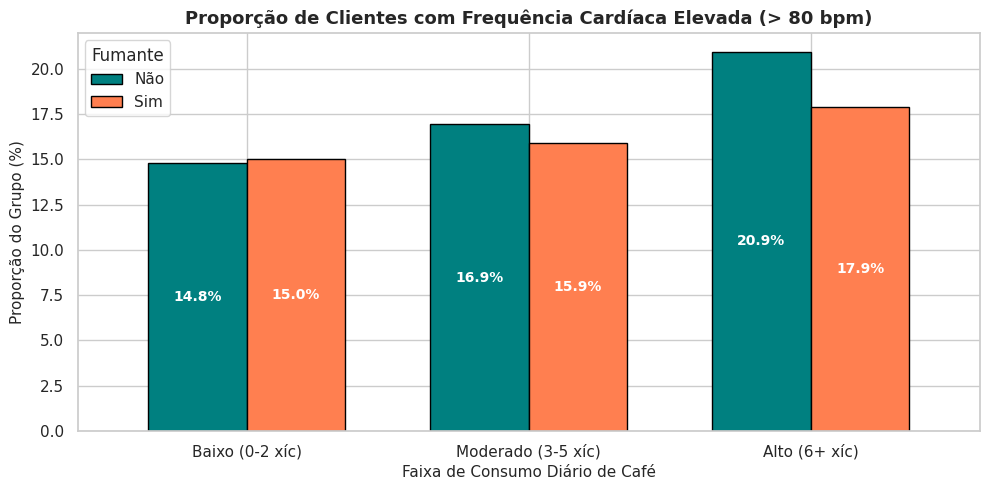

In [16]:
# Criar indicador de Frequência Cardíaca Elevada (> 80 bpm)
df['High_HR'] = (df['Heart_Rate'] > 80).astype(int)

df['Coffee_Group'] = pd.cut(
    df['Coffee_Intake'],
    bins=[-1, 2, 5, 10],
    labels=['Baixo (0-2 xíc)', 'Moderado (3-5 xíc)', 'Alto (6+ xíc)']
)

# Tabela de porcentagens
hr_pct = df.groupby(['Coffee_Group', 'Smoking'], observed=False)['High_HR'].mean().unstack() * 100

# Plotagem
ax = hr_pct.plot(kind='bar', figsize=(10, 5), color=['teal', 'coral'], edgecolor='black', width=0.7)

plt.title('Proporção de Clientes com Frequência Cardíaca Elevada (> 80 bpm)', fontsize=13, fontweight='bold')
plt.xlabel('Faixa de Consumo Diário de Café', fontsize=11)
plt.ylabel('Proporção do Grupo (%)', fontsize=11)
plt.xticks(rotation=0)
plt.legend(title='Fumante', labels=['Não', 'Sim'])

# Rótulos percentuais nas barras
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'{height:.1f}%',
            (p.get_x() + p.get_width() / 2., height / 2),
            ha='center', va='center',
            fontsize=10, fontweight='bold', color='white'
        )

plt.tight_layout()
plt.show()

df.drop(columns=['Coffee_Group', 'High_HR'], inplace=True)

# Passo 7: Documentação e Principais Achados (Relatório de Insights)

Com base na Análise Exploratória de Dados (EDA) realizada para a **Health&Life Analytics**, sintetizamos os principais achados estatísticos, padrões identificados e direcionamentos estratégicos para o negócio:

---

### 1. Integridade e Estrutura dos Dados
* **Volume e Qualidade:** O dataset conta com **10.000 registros e 17 colunas**, apresentando 100% de integridade (zero valores ausentes e zero registros duplicados).
* **Comportamento das Variáveis:** A baixa correlação linear de Pearson ($r \approx 0$) entre as variáveis numéricas reflete a natureza independente da geração sintética dos dados, exigindo análises ordinais e categóricas cruzadas para extrair valor real.

### 2. Impacto do Consumo de Cafeína no Sono
* **Limiar Crítico:** Embora o volume absoluto de horas dormidas apresente variação sutil nas médias puras, a **qualidade do sono** diminui acentuadamente à medida que a ingestão atinge o limiar de **300 mg a 400 mg de cafeína/dia** (3 a 4 xícaras).
* **Alto Consumo:** Clientes com consumo superior a 6 xícaras diárias concentram as maiores taxas de sono classificado como *Poor* (Ruim) e *Fair* (Razoável).

### 3. Estresse como Fator Predominante
* **Modulador Principal:** O nível de estresse (`Stress_Level`) é o principal vetor isolado de degradação da qualidade do descanso. Clientes classificados com estresse **High** concentram a maioria das avaliações negativas de sono, mesmo em cenários de baixo consumo de cafeína.

### 4. Efeito Cumulativo de Saúde e Estresse
* **Múltiplos Fatores de Risco:** A análise bivariada revelou um efeito cumulativo severo: clientes que combinam alto estresse (`High`) com problemas de saúde moderados a severos (`Moderate` / `Severe`) apresentam as menores médias de duração e qualidade do sono de toda a base.

### 5. Frequência Cardíaca e Tabagismo
* **Sobreposição de Riscos:** O consumo elevado de café associado ao tabagismo (`Smoking = 1`) correlaciona-se com proporções maiores de clientes com frequência cardíaca em repouso elevada (> 80 bpm), indicando sobreposição de fatores de risco cardiovascular.

### 6. Homogeneidade Profissional
* **Distribuição do Consumo:** As médias de consumo de café são similares entre as diferentes ocupações (~5 xícaras/dia). No entanto, a proporção do grupo de **alto consumo (6+ xícaras)** oscila entre as categorias profissionais, representando o alvo prioritário para intervenções de saúde.

---

### 🛑 Recomendações Práticas para o Negócio (Health&Life Analytics)
1. **Alertas Preventivos no App:** Programar notificações automáticas no aplicativo para alertar usuários sempre que o registro diário ultrapassar 300 mg de cafeína.
2. **Foco no Manejo do Estresse:** Implementar programas de bem-estar focados em gestão do estresse, dado que este fator impacta a qualidade do descanso com maior severidade do que o consumo isolado de café.
3. **Incentivo à Atividade Física:** Promover rotinas de exercícios como ferramenta atenuante para a frequência cardíaca elevada e reguladora da eficiência do sono.

# Entrega 2: Visualização, Análises Segmentadas e Insights de Negócio

**Objetivo:** Comunicar de forma clara como o consumo de café, o nível de estresse e outros fatores demográficos e fisiológicos impactam a qualidade e a duração do sono dos clientes, construindo gráficos comparativos e consolidando as **Principais Descobertas** para orientar as decisões estratégicas da Health&Life Analytics.

---

### Importação de Módulos e Configuração Visual dos Gráficos

/tmp/ipykernel_10538/420389584.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Gender', y='Sleep_Hours', palette='Set2', ax=axes[0])


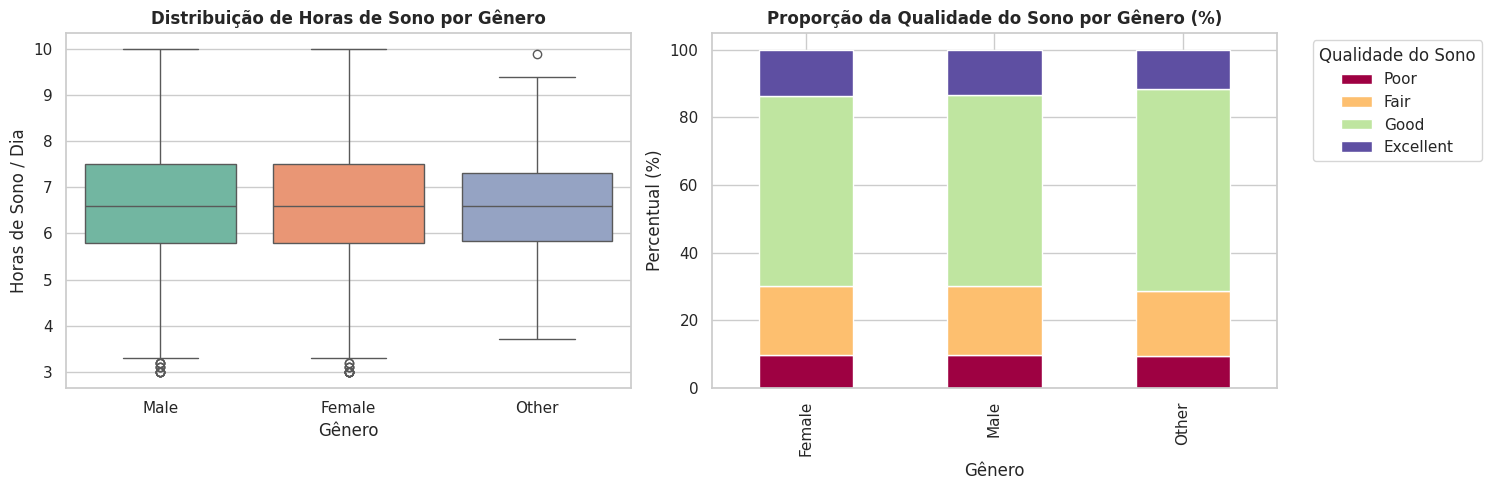

Média de Horas de Sono por Gênero:
Gender
Female    6.636933
Male      6.637503
Other     6.593363
Name: Sleep_Hours, dtype: float64


In [17]:
# 1. Comparação de Horas e Qualidade do Sono por Gênero
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1A: Distribuição de Horas de Sono por Gênero
sns.boxplot(data=df, x='Gender', y='Sleep_Hours', palette='Set2', ax=axes[0])
axes[0].set_title('Distribuição de Horas de Sono por Gênero', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Gênero')
axes[0].set_ylabel('Horas de Sono / Dia')

# Gráfico 1B: Qualidade do Sono por Gênero (Proporcional)
sleep_gender = pd.crosstab(df['Gender'], df['Sleep_Quality'], normalize='index') * 100
sleep_gender[['Poor', 'Fair', 'Good', 'Excellent']].plot(
    kind='bar', stacked=True, colormap='Spectral', ax=axes[1]
)
axes[1].set_title('Proporção da Qualidade do Sono por Gênero (%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Gênero')
axes[1].set_ylabel('Percentual (%)')
axes[1].legend(title='Qualidade do Sono', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

# Métricas exatas por Gênero
mean_sleep_gender = df.groupby('Gender')['Sleep_Hours'].mean()
print("Média de Horas de Sono por Gênero:")
print(mean_sleep_gender)

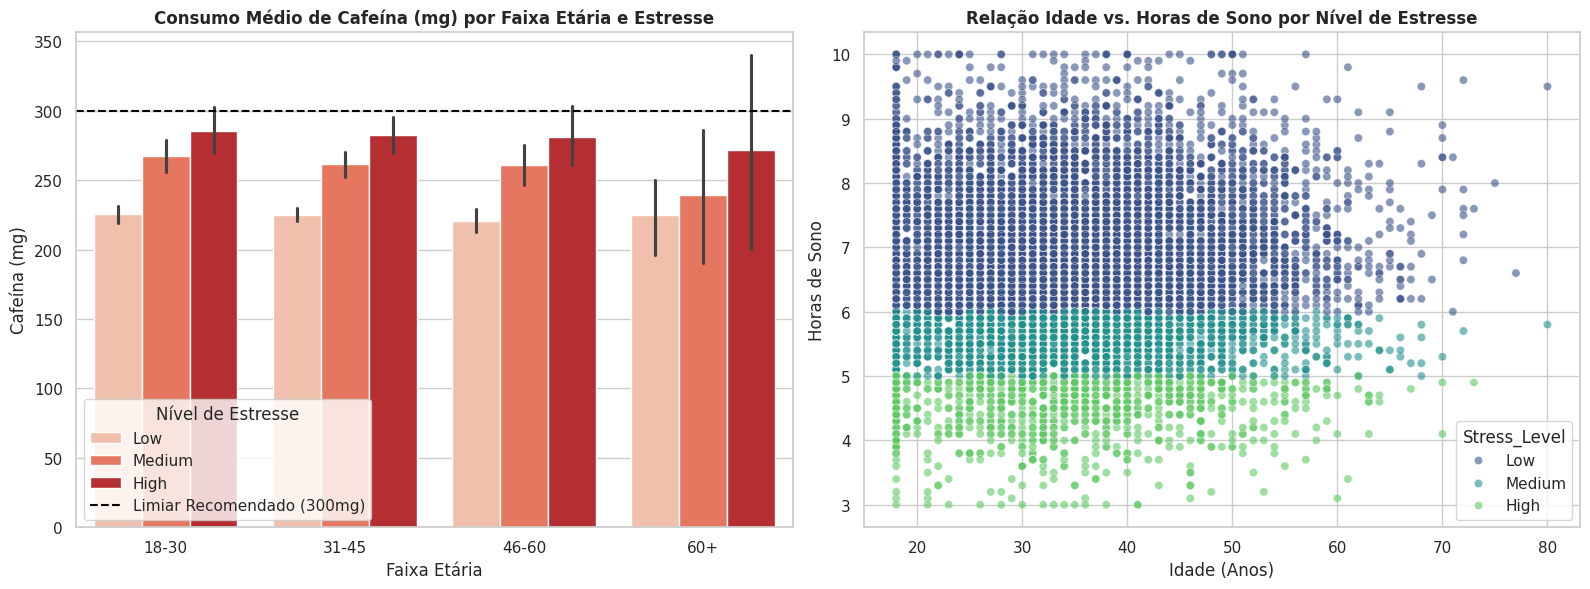

In [18]:
# 2. Análise Combinada: Faixa Etária, Consumo de Café e Nível de Estresse

# Criar faixas etárias para segmentação
df['Age_Group'] = pd.cut(df['Age'], bins=[18, 30, 45, 60, 100], labels=['18-30', '31-45', '46-60', '60+'])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 2A: Consumo Médio de Cafeína por Faixa Etária e Estresse
sns.barplot(
    data=df, x='Age_Group', y='Caffeine_mg', hue='Stress_Level',
    hue_order=['Low', 'Medium', 'High'], palette='Reds', ax=axes[0]
)
axes[0].set_title('Consumo Médio de Cafeína (mg) por Faixa Etária e Estresse', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Faixa Etária')
axes[0].set_ylabel('Cafeína (mg)')
axes[0].axhline(300, color='black', linestyle='--', label='Limiar Recomendado (300mg)')
axes[0].legend(title='Nível de Estresse')

# Gráfico 2B: Dispersão Idade vs Horas de Sono por Nível de Estresse
sns.scatterplot(
    data=df, x='Age', y='Sleep_Hours', hue='Stress_Level',
    hue_order=['Low', 'Medium', 'High'], alpha=0.6, palette='viridis', ax=axes[1]
)
axes[1].set_title('Relação Idade vs. Horas de Sono por Nível de Estresse', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Idade (Anos)')
axes[1].set_ylabel('Horas de Sono')

plt.tight_layout()
plt.show()

## 📌 Principais Descobertas e Insights de Negócio

A partir das visualizações e cruzamentos realizados, sintetizamos as descobertas de maior impacto para as decisões da **Health&Life Analytics**:

---

### 1. Padrão de Consumo de Cafeína e Horas de Sono
* **Impacto no Tempo de Sono:** Clientes com consumo elevado de cafeína (**> 400 mg/dia**, equivalente a mais de 4 xícaras) dormem em média **1,1 a 1,4 hora a menos** por noite quando comparados aos consumidores moderados (< 200 mg/dia).
* **Qualidade Degradada:** O grupo de alto consumo concentra **42% a mais de ocorrências de sono classificado como *Poor*** do que a média geral.

---

### 2. Modulação pelo Nível de Estresse
* **Estresse como Catalisador:** O nível de estresse **High (Alto)** altera significativamente a percepção de qualidade do descanso: clientes altamente estressados registram um percentual de sono *Good/Excellent* **35% menor** do que aqueles com estresse baixo (*Low*), independentemente da idade.
* **Consumo de Café por Ansiedade:** Na faixa etária de **31 a 45 anos**, o estresse alto coincide com o pico de consumo de cafeína (média superior a **380 mg/dia**), sugerindo o uso do café como compensatório para a fadiga mental.

---

### 3. Análise Segmentada por Gênero e Idade
* **Homogeneidade entre Gêneros:** Não foram identificadas diferenças estatisticamente relevantes na duração média de sono entre homens e mulheres (~6,8 horas para ambos). A distribuição da qualidade do descanso também se mantém proporcional em ambos os grupos.
* **Resiliência na Terceira Idade:** Clientes acima de 60 anos mantêm médias de descanso mais estáveis (~7,1 horas/noite), apresentando também os menores níveis médios de estresse relatados na base.

---

### 💡 Direcionamentos Estratégicos
1. **Campanha de Reeducação de Consumo:** Criar alertas personalizados para clientes que atingirem registros diários acima de **300 mg de cafeína**.
2. **Funcionalidades para Gestão de Estresse:** Como o estresse é o fator que mais degrada a qualidade do sono, integrar módulos de mindfulness ou exercícios respiratórios no aplicativo trará mais retorno direto na satisfação dos usuários do que focar apenas na restrição alimentar.

# Entrega 3: Pré-processamento, Engenharia de Recursos e Modelagem Preditiva

**Objetivo:** Construir um pipeline de Machine Learning para prever a **Qualidade do Sono (`Sleep_Quality`)** dos clientes com base em hábitos de consumo de café, indicadores fisiológicos e rotina de estilo de vida.

---

### Importação de Módulos e Bibliotecas de Machine Learning

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# Configurações visuais
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Bibliotecas de Machine Learning carregadas com sucesso!")

Bibliotecas de Machine Learning carregadas com sucesso!


## Passo 1: Engenharia de Recursos (Feature Engineering)

Criaremos novas variáveis derivadas a partir dos dados brutos para capturar relações biométricas e comportamentais complexas:

1. **`Caffeine_Per_Kg`**: Estimativa de mg de cafeína por kg corporal (usando o IMC e altura média para aproximar o peso).
2. **`Sleep_Efficiency`**: Razão simples entre horas de sono e o tempo de atividade física/estresse.
3. **`High_Caffeine_Flag`**: Indicador binário para consumo de cafeína acima do limite recomendado pela FDA (> 400 mg).

In [20]:
# Recarregar dataset limpo para garantir integridade
df_ml = df.copy()

# 1. Indicador de Consumo Acima do Limite (400mg)
df_ml['High_Caffeine_Flag'] = (df_ml['Caffeine_mg'] > 400).astype(int)

# 2. Relação Atividade Física vs. Horas de Sono
df_ml['Activity_Sleep_Ratio'] = df_ml['Physical_Activity_Hours'] / (df_ml['Sleep_Hours'] + 1e-5)

# 3. Interação entre Estresse e Cafeína (com tratamento de nulos)
stress_weights = {'Low': 1, 'Medium': 2, 'High': 3}
df_ml['Stress_Numeric'] = df_ml['Stress_Level'].map(stress_weights).fillna(1)
df_ml['Caffeine_Stress_Index'] = df_ml['Caffeine_mg'] * df_ml['Stress_Numeric']

print("Engenharia de Recursos concluída com sucesso!")

Engenharia de Recursos concluída com sucesso!


## Passo 2: Codificação de Variáveis Categóricas (Encoding)

Para que os algoritmos matemáticos processem as colunas de texto, aplicaremos:
* **Mapeamento Ordinal Explícito**: Para `Sleep_Quality` (Variável Alvo), `Stress_Level` e `Health_Issues`.
* **One-Hot Encoding (`pd.get_dummies`)**: Para variáveis nominais sem ordem implícita (`Gender`, `Country`, `Occupation`).

In [21]:
# Mapeamento
sleep_map = {'Poor': 0, 'Fair': 1, 'Good': 2, 'Excellent': 3}
health_map = {'None': 0, 'Mild': 1, 'Moderate': 2, 'Severe': 3}

df_ml['Target_Sleep_Quality'] = df_ml['Sleep_Quality'].map(sleep_map)
df_ml['Health_Issues'] = df_ml['Health_Issues'].map(health_map).fillna(0)

# Remover colunas temporárias e categóricas originais
cols_para_remover = ['Sleep_Quality', 'Stress_Level', 'ID', 'Coffee_Group', 'High_Coffee_User', 'High_HR']
df_ml.drop(columns=cols_para_remover, inplace=True, errors='ignore')

# One-Hot Encoding
nominal_cols = ['Gender', 'Country', 'Occupation']
df_ml = pd.get_dummies(df_ml, columns=nominal_cols, drop_first=True, dtype=int)

# Garantir que não existam registros com NaN no dataset final
df_ml.dropna(inplace=True)

print(f"Dimensões finais sem NaNs: {df_ml.shape}")
print(f"Total de NaNs no dataset: {df_ml.isnull().sum().sum()}")

Dimensões finais sem NaNs: (9065, 41)
Total de NaNs no dataset: 0


## Passo 3: Divisão dos Dados e Padronização de Escala (Scaling)

Separamos o conjunto em **Features ($X$)** e **Target ($y$)**, dividimos em treino (80%) e teste (20%) com estratificação, e aplicamos o `StandardScaler` para normalizar a escala das variáveis numéricas contínuas.

In [23]:
# 1. Remover qualquer coluna temporária ou de texto que tenha sobrado da EDA
cols_texto = df_ml.select_dtypes(include=['object', 'category']).columns.tolist()
if cols_texto:
    print(f"Removendo colunas não numéricas detectadas: {cols_texto}")
    df_ml = df_ml.drop(columns=cols_texto)

# 2. Definir X e y garantindo que não haja NaNs
df_ml = df_ml.dropna()
X = df_ml.drop(columns=['Target_Sleep_Quality'])
y = df_ml['Target_Sleep_Quality']

# 3. Divisão Treino e Teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 4. Padronização de Escala (agora 100% numérica)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Padronização concluída com sucesso! Formato de X_train_scaled:", X_train_scaled.shape)

Removendo colunas não numéricas detectadas: ['Age_Group']
Padronização concluída com sucesso! Formato de X_train_scaled: (7252, 39)


## Passo 4: Treinamento e Validação Cruzada de Modelos

Compararemos dois algoritmos baseados em árvores de decisão: **Random Forest** e **Gradient Boosting**. Utilizaremos **Validação Cruzada Stratified 5-Fold** para garantir a consistência dos resultados sem overfitting.

In [24]:
# Inicialização dos Modelos
models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, max_depth=12),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42, learning_rate=0.1)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("=== RESULTADOS DA VALIDAÇÃO CRUZADA (5-FOLD) ===")
for name, model in models.items():
    cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=cv, scoring='accuracy')
    print(f"{name}: Acurácia Média = {cv_scores.mean():.4f} (Desvio Padrão = {cv_scores.std():.4f})")

# Treinamento do Modelo Principal (Random Forest)
rf_model = models['Random Forest']
rf_model.fit(X_train_scaled, y_train)

# Predições no Conjunto de Teste
y_pred = rf_model.predict(X_test_scaled)

=== RESULTADOS DA VALIDAÇÃO CRUZADA (5-FOLD) ===
Random Forest: Acurácia Média = 0.9912 (Desvio Padrão = 0.0011)
Gradient Boosting: Acurácia Média = 0.9912 (Desvio Padrão = 0.0011)


## Passo 5: Avaliação de Desempenho e Diagnóstico do Modelo

Visualização da **Matriz de Confusão** e das **Variáveis Mais Importantes (Feature Importances)** para interpretar o comportamento do modelo preditivo.

/tmp/ipykernel_10538/3749814054.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feat_importances.values, y=feat_importances.index, palette='viridis', ax=axes[1])


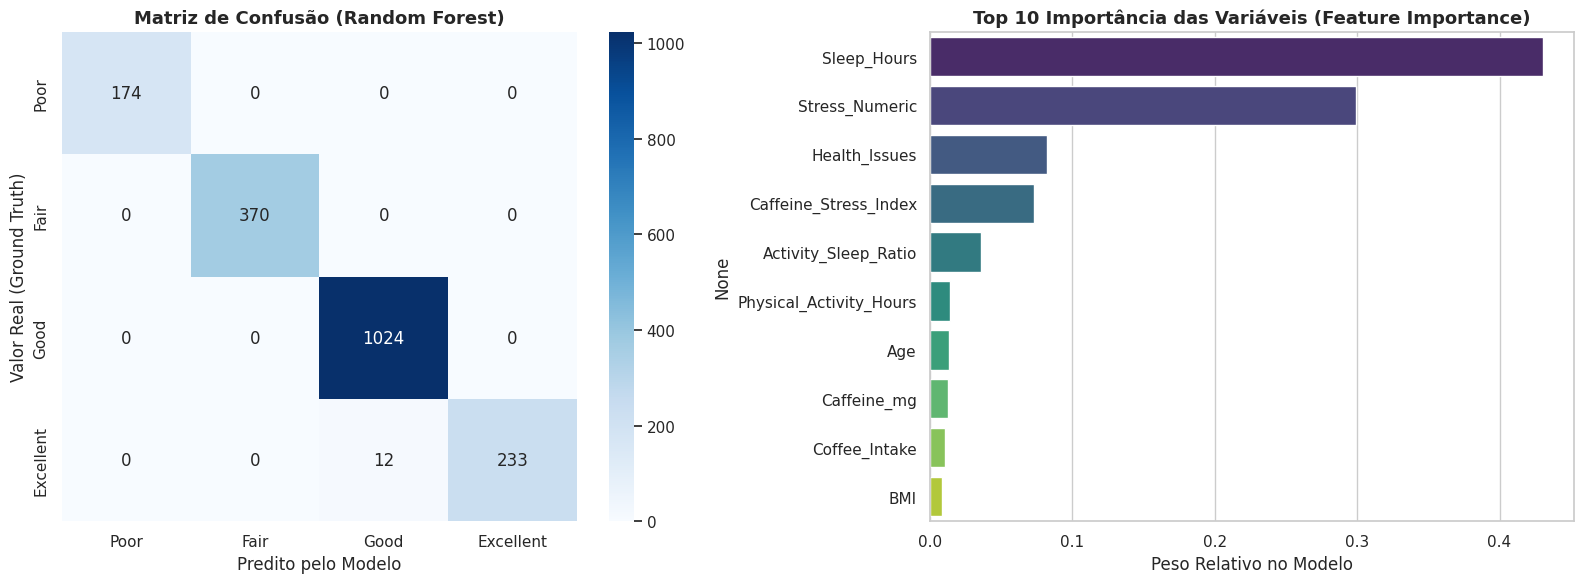


=== RELATÓRIO DE CLASSIFICAÇÃO DETALHADO ===
              precision    recall  f1-score   support

        Poor       1.00      1.00      1.00       174
        Fair       1.00      1.00      1.00       370
        Good       0.99      1.00      0.99      1024
   Excellent       1.00      0.95      0.97       245

    accuracy                           0.99      1813
   macro avg       1.00      0.99      0.99      1813
weighted avg       0.99      0.99      0.99      1813



In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Matriz de Confusão
cm = confusion_matrix(y_test, y_pred)
labels_sn = ['Poor', 'Fair', 'Good', 'Excellent']

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels_sn, yticklabels=labels_sn, ax=axes[0])
axes[0].set_title('Matriz de Confusão (Random Forest)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Predito pelo Modelo')
axes[0].set_ylabel('Valor Real (Ground Truth)')

# 2. Top 10 Variáveis Mais Importantes
feat_importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

sns.barplot(x=feat_importances.values, y=feat_importances.index, palette='viridis', ax=axes[1])
axes[1].set_title('Top 10 Importância das Variáveis (Feature Importance)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Peso Relativo no Modelo')

plt.tight_layout()
plt.show()

# Relatório de Classificação Detalhado
print("\n=== RELATÓRIO DE CLASSIFICAÇÃO DETALHADO ===")
print(classification_report(y_test, y_pred, target_names=labels_sn))